# Move-IIT-HPE — EventPointPose energy and real-time factor

**5-method comparison at existing operating points.** This notebook extends the `ExpEnergy/Notebooks/MoveIIT_Energy_RTF_Analysis.ipynb` style and metrics. Three original MoveEnet operating points are read from their **already-measured** energy session; two new EventPointPose points (5/50 Hz) are measured with the *same* `ExpEnergy/measure_energy.py`.

**What is measured:** whole-command wall-clock runtime (includes model startup and dataset loading); Intel RAPL **CPU-package** energy plus NVIDIA NVML **device-wide GPU** energy. This is not process-specific energy and is *not* an inference-latency benchmark. `RTF = sum(mean runtime per recording) / sum(exact ATIS input duration)`; lower is faster, below 1 means faster than real time.

**Design:** 12 **identical** Move-IIT sequences, 5 technical repeats per operating point; input duration = first to last ATIS AE packet timestamp. CPU/GPU energy and runtime are compared descriptively across **different measurement sessions**; same physical GPU is checked but day/temperature/background-load differences cannot be removed retrospectively.

**No accuracy claims:** optional plots combine only the same 12 sequences' previously computed **matched and valid-2D-GT** predictions. Marker mapping and temporal GT offset remain provisional; no models are rerun.

## 1. Setup — session paths, uncertainty and shared plotting style

Run this notebook from `ExpEnergy/Notebooks/` on the **host** after the EPP runner succeeds. Change `EPP_SESSION` and `BASELINE_SESSION` if your host paths differ. Repeated runs only overwrite this notebook's derived output tables and figures, never the measured-energy CSVs.

In [7]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from IPython.display import display

BASELINE_SESSION = Path(
    "/data/MoveEnet_OFK_results/Energy/"
    "moveiit_energy_rtf_roi35_gain1_20261103"
)

EPP_SESSION = Path(
    "/data/MoveEnet_OFK_results/Energy/"
    "moveiit_eventpointpose_energy_rtf_stretch_v1"
)

RESULTS = EPP_SESSION / "comparison_with_movenet"
FIGURES = RESULTS / "figures"

AUTO_ANALYZE = False
SAVE_FIGURES = True
EXPORT_FORMATS = ('svg', 'pdf', 'png')
DPI = 300

ORDER = ['movenet_50hz', 'movenet_5hz', 'moveenetofk_5hz',
         'eventpointpose_5hz', 'eventpointpose_50hz']
LABEL = {
    'movenet_50hz': 'MoveEnet-only (50 Hz)',
    'movenet_5hz': 'MoveEnet-only (5 Hz)',
    'moveenetofk_5hz': 'MoveEnetOFK (5 Hz, flow 200 Hz)',
    'eventpointpose_5hz': 'EventPointPose (5 Hz)',
    'eventpointpose_50hz': 'EventPointPose (50 Hz)',
}
COLORS = {
    'movenet_50hz': '#45678A', 'movenet_5hz': '#98AEC5',
    'moveenetofk_5hz': '#D17E46',
    'eventpointpose_5hz': '#3D9186', 'eventpointpose_50hz': '#1E605A',
}
CPU_COLOR = '#45678A'
GPU_COLOR = '#D17E46'
FIGSIZE = (9.0, 4.9)
FONTSIZE = 11
mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': FONTSIZE,
    'axes.labelsize': FONTSIZE, 'xtick.labelsize': FONTSIZE-1,
    'ytick.labelsize': FONTSIZE-1, 'legend.fontsize': FONTSIZE-1,
    'svg.fonttype': 'none', 'pdf.fonttype': 42,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'savefig.facecolor': 'white',
})
if not BASELINE_SESSION.is_dir() and (Path('/data/MoveEnet_OFK_results/Energy') / BASELINE_SESSION.name).is_dir():
    BASELINE_SESSION = Path('/data/MoveEnet_OFK_results/Energy') / BASELINE_SESSION.name
if not EPP_SESSION.is_dir() and (BASELINE_SESSION.parent / EPP_SESSION.name).is_dir():
    EPP_SESSION = BASELINE_SESSION.parent / EPP_SESSION.name
RESULTS = EPP_SESSION / 'comparison_with_movenet'
FIGURES = RESULTS / 'figures'
print('Original MoveEnet energy session:', BASELINE_SESSION)
print('EventPointPose energy session:', EPP_SESSION)
print('Comparison output:', RESULTS)

Original MoveEnet energy session: /data/MoveEnet_OFK_results/Energy/moveiit_energy_rtf_roi35_gain1_20261103
EventPointPose energy session: /data/MoveEnet_OFK_results/Energy/moveiit_eventpointpose_energy_rtf_stretch_v1
Comparison output: /data/MoveEnet_OFK_results/Energy/moveiit_eventpointpose_energy_rtf_stretch_v1/comparison_with_movenet


## 2. Validate the measurement protocol and create analysis tables

The validator checks `OK` meter records, exact input spans, end-of-file counters in every EPP log, all 5 repeats, all 12 recordings, no duplicate successful attempts, physical GPU identity, and the original baseline protocol. It computes per-sequence means **before** dataset aggregation and uses 5,000 sequence-level bootstrap resamples (the five technical repeats are not independent sequence observations).

In [8]:
# Import the sibling analysis script; the shipped runner/analysis/notebook live
# in the same ExpEnergy directory hierarchy.
EXPERIMENT_DIR = Path.cwd().resolve()
if EXPERIMENT_DIR.name == 'Notebooks':
    EXPERIMENT_DIR = EXPERIMENT_DIR.parent
else:
    # Also work when Jupyter was opened from another current directory.
    candidates = [Path('/workspace/moveEnetFlow/experiments/ExpEnergy'),
                  Path.cwd()/'moveEnetFlow/experiments/ExpEnergy']
    EXPERIMENT_DIR = next((p for p in candidates if
        (p/'analyze_moveiit_eventpointpose_energy_rtf.py').is_file()), EXPERIMENT_DIR)
if str(EXPERIMENT_DIR) not in sys.path:
    sys.path.insert(0, str(EXPERIMENT_DIR))
from analyze_moveiit_eventpointpose_energy_rtf import run

if AUTO_ANALYZE:
    per_sample, summary, paired = run(EPP_SESSION, BASELINE_SESSION,
                                      output=RESULTS, strict=True)
else:
    per_sample = pd.read_csv(RESULTS/'energy_runtime_by_sample_5methods.csv')
    summary = pd.read_csv(RESULTS/'energy_runtime_dataset_summary_5methods.csv')
    paired = pd.read_csv(RESULTS/'paired_differences_5methods.csv')
summary = summary.set_index('model').loc[ORDER].reset_index()
assert len(per_sample) == 12*5 and summary.n_sequences.eq(12).all(), 'Incomplete 12-sequence/5-method comparison'
assert np.isfinite(summary.select_dtypes(include='number')).all().all(), 'Invalid summary values'
FIGURES.mkdir(parents=True, exist_ok=True)
display(summary[['method','energy_mean_j','cpu_energy_mean_j','gpu_energy_mean_j',
                 'wall_mean_s','real_time_factor','energy_j_per_input_second']].round(3))

,method,energy_mean_j,cpu_energy_mean_j,gpu_energy_mean_j,wall_mean_s,real_time_factor,energy_j_per_input_second
0,MoveEnet only (50 Hz),498.767,334.159,164.608,12.138,0.736,30.244
1,MoveEnet only (5 Hz),237.060,142.099,94.961,6.658,0.404,14.375
2,MoveEnetOFK (5 Hz; OF 200 Hz),257.738,155.297,102.440,7.267,0.441,15.629
3,EventPointPose (5 Hz),2379.647,1415.404,964.243,71.366,4.327,144.297
4,EventPointPose (50 Hz),2982.064,1894.297,1087.766,79.172,4.801,180.826


## 3. Shared figure helpers

Standalone figures saved in SVG, PDF, PNG. Colors/typography are consistent with the existing Move-IIT energy notebook. Confidence intervals denote the **95% recording bootstrap**, not variability of individual measurement repeats.

In [9]:
xx = np.arange(len(ORDER), dtype=float)
xticklabels = [LABEL[m] for m in ORDER]

def save(fig, basename):
    fig.tight_layout()
    if SAVE_FIGURES:
        for ext in EXPORT_FORMATS:
            fig.savefig(FIGURES / '{}.{}'.format(basename,ext),
                        dpi=DPI, bbox_inches='tight')
    plt.show()

def decorate(ax, label):
    ax.set_xticks(xx)
    ax.set_xticklabels(xticklabels, rotation=17, ha='right')
    ax.set_ylabel(label)
    ax.grid(axis='y', alpha=.22)
    ax.set_axisbelow(True)

def asym_ci(value, low, high):
    v = np.asarray(value, float)
    a = np.asarray(low, float)
    b = np.asarray(high, float)
    return np.vstack((np.maximum(0,v-a), np.maximum(0,b-v)))

## 4. Measured compute energy — CPU package + GPU device

Stacked bars correspond to the mean of complete-recording measurements. Energy includes background device consumption during the measurement window; no idle baseline is subtracted.

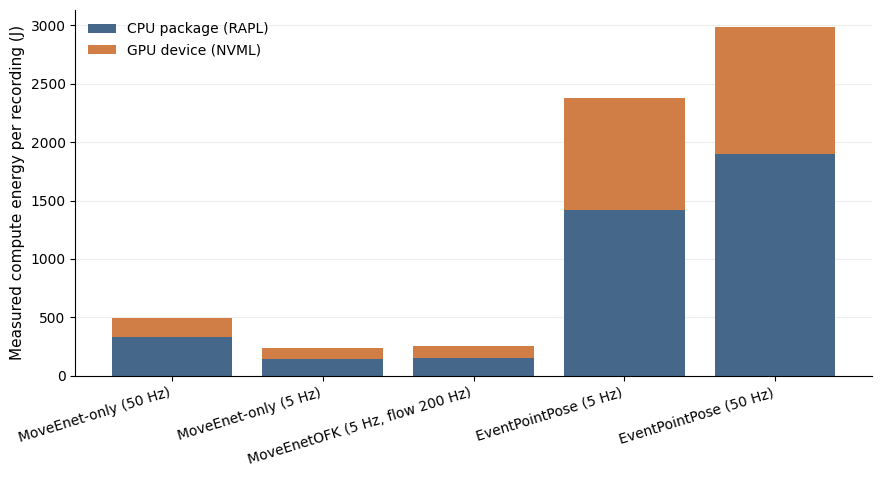

In [10]:
fig,ax = plt.subplots(figsize=FIGSIZE)
ax.bar(xx, summary.cpu_energy_mean_j, color=CPU_COLOR, label='CPU package (RAPL)')
ax.bar(xx, summary.gpu_energy_mean_j, bottom=summary.cpu_energy_mean_j,
       color=GPU_COLOR, label='GPU device (NVML)')
decorate(ax, 'Measured compute energy per recording (J)')
ax.legend(frameon=False)
save(fig, 'epp_movenet_cpu_gpu_energy')

## 5. Total measured energy with 95% bootstrap confidence intervals

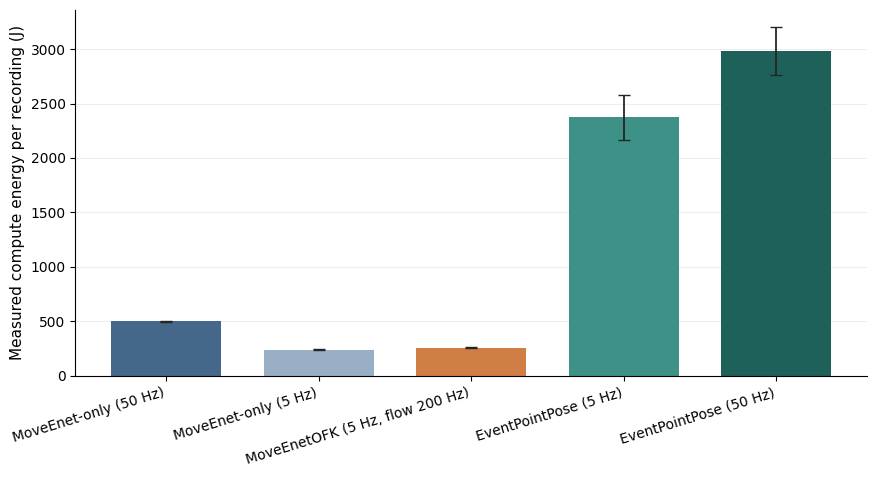

In [11]:
fig,ax = plt.subplots(figsize=FIGSIZE)
v = summary.energy_mean_j.to_numpy(float)
e = asym_ci(v, summary.energy_ci95_low, summary.energy_ci95_high)
ax.bar(xx,v,color=[COLORS[m] for m in ORDER],width=.72)
ax.errorbar(xx,v,yerr=e,fmt='none',ecolor='#252525',capsize=4,lw=1.3)
decorate(ax,'Measured compute energy per recording (J)')
save(fig,'epp_movenet_energy_ci95')

## 6. Real-time factor (RTF)

`RTF = sum(mean measured whole-command runtime over recordings) / sum(ATIS first-to-last event time)`.
An RTF below 1 indicates faster-than-real-time offline processing; this is *not* per-pose inference latency.

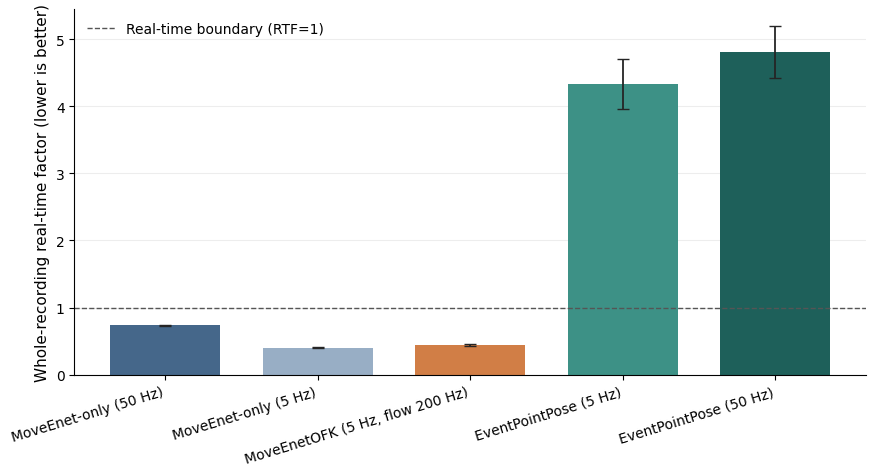

In [12]:
fig,ax = plt.subplots(figsize=FIGSIZE)
v = summary.real_time_factor.to_numpy(float)
e = asym_ci(v,summary.rtf_ci95_low,summary.rtf_ci95_high)
ax.bar(xx,v,color=[COLORS[m] for m in ORDER],width=.72)
ax.errorbar(xx,v,yerr=e,fmt='none',ecolor='#252525',capsize=4,lw=1.3)
ax.axhline(1.0,ls='--',color='#555555',lw=1,label='Real-time boundary (RTF=1)')
decorate(ax,'Whole-recording real-time factor (lower is better)')
ax.legend(frameon=False)
save(fig,'epp_movenet_rtf_ci95')

## 7. Complete-recording wall-clock runtime

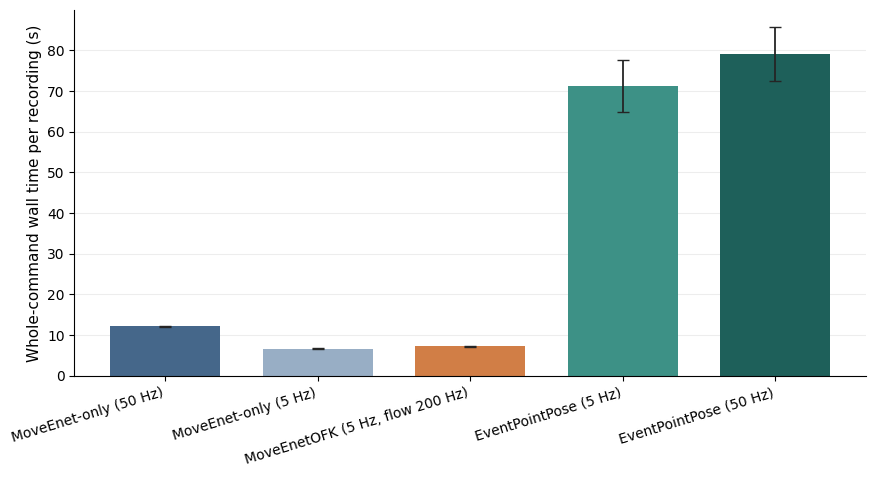

In [13]:
fig,ax = plt.subplots(figsize=FIGSIZE)
v = summary.wall_mean_s.to_numpy(float)
e = asym_ci(v,summary.wall_ci95_low,summary.wall_ci95_high)
ax.bar(xx,v,color=[COLORS[m] for m in ORDER],width=.72)
ax.errorbar(xx,v,yerr=e,fmt='none',ecolor='#252525',capsize=4,lw=1.3)
decorate(ax,'Whole-command wall time per recording (s)')
save(fig,'epp_movenet_wall_time_ci95')

## 8. Input-normalized measured energy

For sequences with different durations, the dataset-level normalization is `sum(mean energy per recording) / sum(ATIS input seconds)` in J per input second, **not** electrical power.

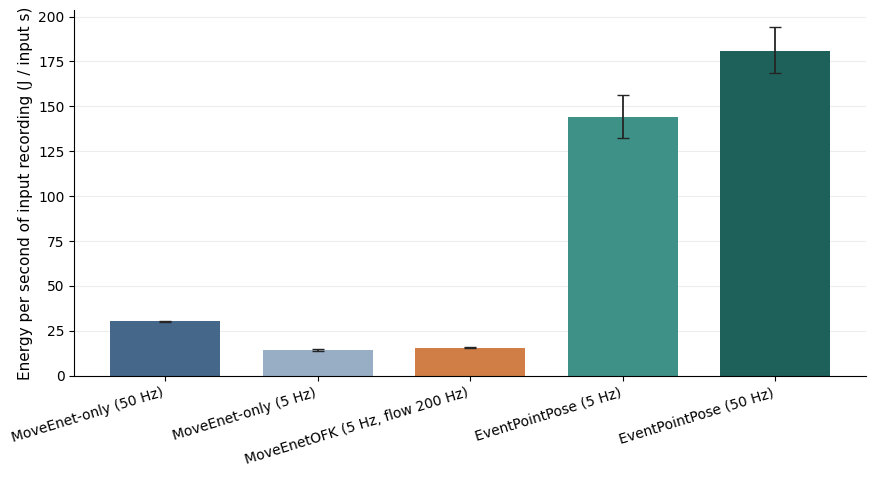

In [14]:
fig,ax = plt.subplots(figsize=FIGSIZE)
v = summary.energy_j_per_input_second.to_numpy(float)
e = asym_ci(v,summary.normalized_energy_ci95_low,
            summary.normalized_energy_ci95_high)
ax.bar(xx,v,color=[COLORS[m] for m in ORDER],width=.72)
ax.errorbar(xx,v,yerr=e,fmt='none',ecolor='#252525',capsize=4,lw=1.3)
decorate(ax,'Energy per second of input recording (J / input s)')
save(fig,'epp_movenet_energy_per_input_second')

## 9. Paired comparisons on the same 12 sequences

Positive energy or runtime saving (%) means the **target method uses less** than the reference. The CI uses common recording resamples for both methods, not the overlap of independent confidence bands.

,comparison,energy_saving_pct,energy_saving_ci95_low,energy_saving_ci95_high,runtime_saving_pct,runtime_saving_ci95_low,runtime_saving_ci95_high
0,EventPointPose (5 Hz) vs MoveEnet-only (5 Hz),-903.82,-971.51,-828.19,-971.88,-1045.33,-893.50
1,"EventPointPose (5 Hz) vs MoveEnetOFK (5 Hz, fl...",-823.28,-881.05,-760.53,-882.00,-947.67,-812.26
2,EventPointPose (5 Hz) vs MoveEnet-only (50 Hz),-377.11,-412.30,-340.51,-487.96,-533.01,-441.52
3,EventPointPose (50 Hz) vs MoveEnet-only (50 Hz),-497.89,-534.61,-460.78,-552.27,-597.78,-505.15
4,EventPointPose (50 Hz) vs EventPointPose (5 Hz),-25.32,-27.46,-23.55,-10.94,-11.80,-10.13
5,"MoveEnetOFK (5 Hz, flow 200 Hz) vs MoveEnet-on...",48.33,47.34,49.45,40.13,39.29,40.95


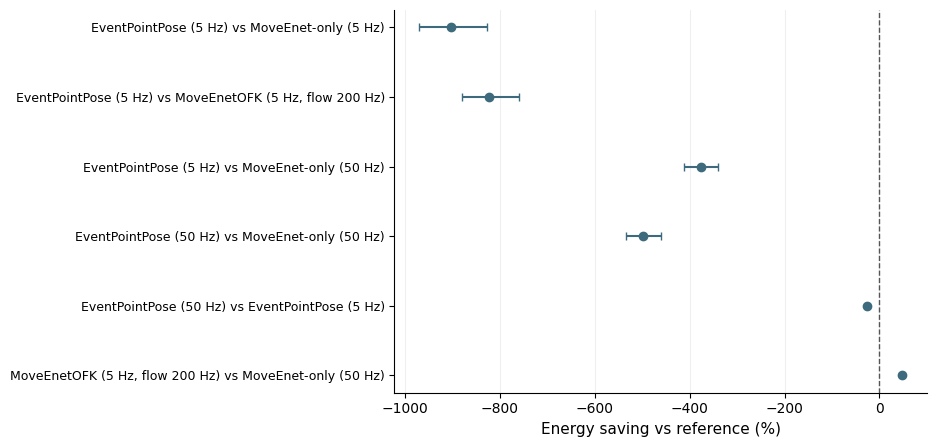

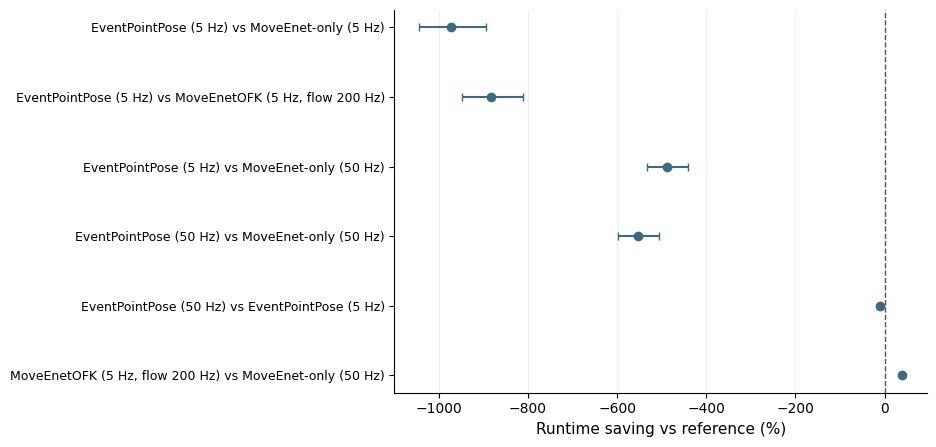

In [15]:
paired = paired.copy()
paired['comparison'] = paired['method'].map(LABEL) + ' vs ' + paired['reference'].map(LABEL)
display(paired[['comparison','energy_saving_pct','energy_saving_ci95_low',
                'energy_saving_ci95_high','runtime_saving_pct',
                'runtime_saving_ci95_low','runtime_saving_ci95_high']].round(2))
for metric,ci_label,filename in [
        ('energy_saving_pct','Energy saving vs reference (%)','epp_movenet_paired_energy_savings'),
        ('runtime_saving_pct','Runtime saving vs reference (%)','epp_movenet_paired_runtime_savings')]:
    fig,ax=plt.subplots(figsize=(9.5,4.6))
    yy=np.arange(len(paired))
    vals=paired[metric].to_numpy(float)
    lo=paired[metric.replace('_pct','_ci95_low')].to_numpy(float)
    hi=paired[metric.replace('_pct','_ci95_high')].to_numpy(float)
    ax.errorbar(vals,yy,xerr=asym_ci(vals,lo,hi),fmt='o',color='#3D6A7C',
                markersize=6,capsize=3)
    ax.axvline(0,color='#555555',lw=1,ls='--')
    ax.set_yticks(yy)
    ax.set_yticklabels(paired.comparison,fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel(ci_label)
    ax.grid(axis='x',alpha=.2)
    save(fig,filename)

## 10. Recording-level audit and paired variability

energy_j                     \
model                       eventpointpose_50hz eventpointpose_5hz   
sample_id subject sequence                                           
M01       luna    box_s1               3055.200           2444.319   
M02       luna    drum_f1              3319.706           2707.100   
M03       luna    march_s1             2990.645           2364.941   
M04       luna    sit_f1               3041.723           2515.024   
M05       luna    tennis_s1            2899.095           2254.531   
M06       luna    walk_f1              3533.203           2919.090   
M07       simon   box_f1               2829.229           2260.631   
M08       simon   drum_s1              2277.402           1708.885   
M09       simon   march_f1             3580.586           2883.520   
M10       simon   sit_s1               2419.783           1833.410   
M11       simon   tennis_s1            2681.832           2110.017   
M12       simon   walk_s1              3156.359           2554.298   

                                                                      \
model                       moveenetofk_5hz movenet_50hz movenet_5hz   
sample_id subject sequence                                             
M01       luna    box_s1            251.125      530.496     236.444   
M02       luna    drum_f1           269.949      511.707     240.590   
M03       luna    march_s1          256.130      508.537     236.879   
M04       luna    sit_f1            256.961      497.332     235.177   
M05       luna    tennis_s1         259.361      495.668     232.506   
M06       luna    walk_f1           271.877      507.470     252.000   
M07       simon   box_f1            258.913      486.830     235.420   
M08       simon   drum_s1           241.633      483.235     229.448   
M09       simon   march_f1          271.879      510.304     248.399   
M10       simon   sit_s1            238.445      474.773     226.006   
M11       simon   tennis_s1         249.710      483.602     231.116   
M12       simon   walk_s1           266.872      495.253     240.736   

                               real_time_factor                     \
model                       eventpointpose_50hz eventpointpose_5hz   
sample_id subject sequence                                           
M01       luna    box_s1                  4.776              4.285   
M02       luna    drum_f1                 5.208              4.718   
M03       luna    march_s1                4.625              4.121   
M04       luna    sit_f1                  4.998              4.528   
M05       luna    tennis_s1               4.513              4.061   
M06       luna    walk_f1                 5.870              5.429   
M07       simon   box_f1                  4.564              4.109   
M08       simon   drum_s1                 3.647              3.208   
M09       simon   march_f1                5.954              5.413   
M10       simon   sit_s1                  3.848              3.388   
M11       simon   tennis_s1               4.272              3.827   
M12       simon   walk_s1                 5.321              4.833   

                                                                      
model                       moveenetofk_5hz movenet_50hz movenet_5hz  
sample_id subject sequence                                            
M01       luna    box_s1              0.421        0.730       0.390  
M02       luna    drum_f1             0.434        0.720       0.390  
M03       luna    march_s1            0.414        0.711       0.379  
M04       luna    sit_f1              0.433        0.729       0.398  
M05       luna    tennis_s1           0.436        0.730       0.396  
M06       luna    walk_f1             0.473        0.767       0.438  
M07       simon   box_f1              0.450        0.741       0.410  
M08       simon   drum_s1             0.422        0.728       0.394  
M09       simon   march_f1            0.476        0.767       0.435  
M10 

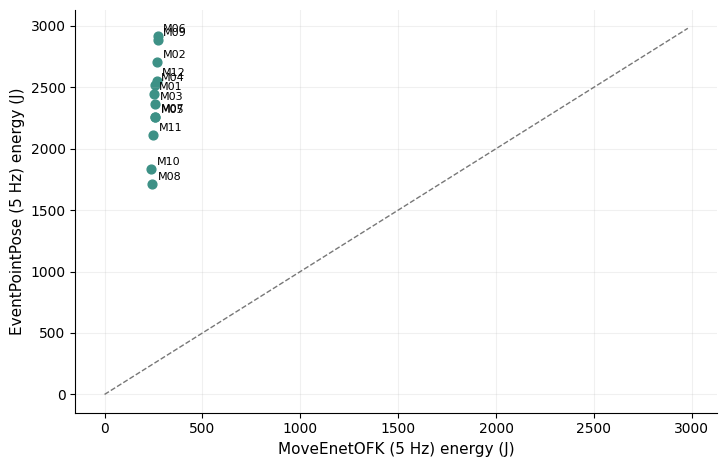

In [16]:
audit=per_sample.pivot(index=['sample_id','subject','sequence'],
    columns='model',values=['energy_j','real_time_factor']).sort_index()
display(audit.round(3))
fig,ax=plt.subplots(figsize=(7.4,4.8))
base=per_sample[per_sample.model=='moveenetofk_5hz'].set_index('sample_id')
epp=per_sample[per_sample.model=='eventpointpose_5hz'].set_index('sample_id')
keys=sorted(set(base.index)&set(epp.index))
assert len(keys)==12, 'Unpaired sample-level data'
ax.scatter(base.loc[keys,'energy_j'],epp.loc[keys,'energy_j'],
           s=40,color=COLORS['eventpointpose_5hz'])
for key in keys:
    ax.annotate(key,(base.at[key,'energy_j'],epp.at[key,'energy_j']),
                xytext=(4,3),textcoords='offset points',fontsize=8)
lim=max(ax.get_xlim()[1],ax.get_ylim()[1])
ax.plot([0,lim],[0,lim],linestyle='--',color='#777777',lw=1)
ax.set_xlabel('MoveEnetOFK (5 Hz) energy (J)')
ax.set_ylabel('EventPointPose (5 Hz) energy (J)')
ax.grid(alpha=.18)
save(fig,'epp_vs_ofk_5hz_paired_energy')

## 11. Optional: energy–accuracy trade-off on the **same 12 recordings**

Use the already-computed `accuracy_by_sample_3methods.csv` from the corrected three-method ExpA notebook. **Do not** join the 12-recording energy benchmark to the 59-recording aggregate accuracy curve; that would combine different populations. This step is skipped if the accuracy CSV is unavailable on the machine running Jupyter. GT mapping/temporal offset are still provisional.

,model,method,energy_mean_j,mpjpe_px,pck02_percent,n_sequences
0,movenet_50hz,MoveEnet-only (50 Hz),498.767,58.621,38.258,12
1,movenet_5hz,MoveEnet-only (5 Hz),237.060,60.502,35.990,12
2,moveenetofk_5hz,"MoveEnetOFK (5 Hz, flow 200 Hz)",257.738,57.492,37.648,12
3,eventpointpose_5hz,EventPointPose (5 Hz),2379.647,87.212,19.112,12
4,eventpointpose_50hz,EventPointPose (50 Hz),2982.064,86.239,19.826,12


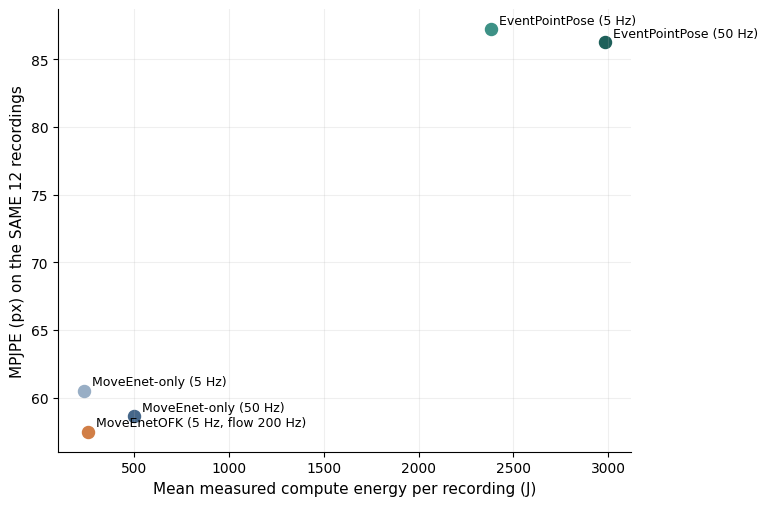

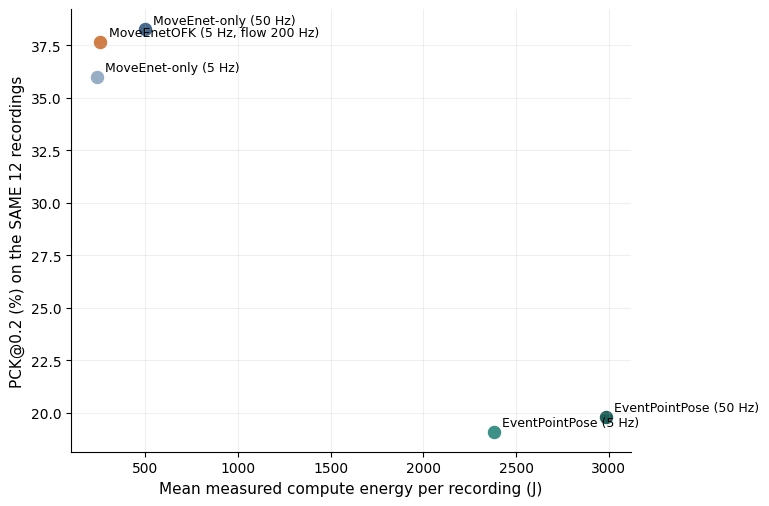

In [17]:
ACCURACY_CSV = Path(os.environ.get(
    'MOVEIIT_EPP_ACCURACY_CSV',
    '/data/MoveEnet_OFK_results/Final_ROI_Gain1/Accuracy/moveiit/ExpA/'
    'analysis_2d_gt_expa_epp_3methods_v2_native_time/accuracy_by_sample_3methods.csv'))
accuracy_joined = None
if not ACCURACY_CSV.is_file():
    print('Accuracy CSV unavailable here; optional energy-accuracy plot skipped:',ACCURACY_CSV)
else:
    acc = pd.read_csv(ACCURACY_CSV)
    method_name = {'moveenet_only': 'movenet',
                   'moveenet_ofk': 'moveenetofk',
                   'eventpointpose': 'eventpointpose'}
    lookup = {
        'movenet_50hz': ('moveenet_only', .02),
        'movenet_5hz': ('moveenet_only', .2),
        'moveenetofk_5hz': ('moveenet_ofk', .2),
        'eventpointpose_5hz': ('eventpointpose', .2),
        'eventpointpose_50hz': ('eventpointpose', .02)}
    accuracy_rows = []
    for row in per_sample.itertuples(index=False):
        name,np_s=lookup[row.model]
        matching = acc[(acc.sample_id=='{}/{}'.format(row.subject,row.sequence)) &
                       (acc.method==name) & np.isclose(acc.net_period_s,np_s)]
        assert len(matching)==1, 'Missing/ambiguous ExpA accuracy: {} {}'.format(row.sample_id,row.model)
        a=matching.iloc[0]
        accuracy_rows.append(dict(sample_id=row.sample_id,model=row.model,
                                  sum_error_px=a.sum_error_px,
                                  valid_mpjpe_joints=a.valid_mpjpe_joints,
                                  correct_pck02=a.correct_pck02,
                                  valid_pck_joints=a.valid_pck_joints))
    acc_subset=pd.DataFrame(accuracy_rows)
    combined_accuracy=per_sample.merge(acc_subset,on=['sample_id','model'],validate='one_to_one')
    pts=[]
    for model,group in combined_accuracy.groupby('model'):
        pts.append(dict(model=model,method=LABEL[model],
                        energy_mean_j=group.energy_j.mean(),
                        mpjpe_px=group.sum_error_px.sum()/group.valid_mpjpe_joints.sum(),
                        pck02_percent=100*group.correct_pck02.sum()/group.valid_pck_joints.sum(),
                        n_sequences=len(group)))
    accuracy_joined=pd.DataFrame(pts).set_index('model').loc[ORDER].reset_index()
    accuracy_joined.to_csv(RESULTS/'energy_accuracy_12samples_5methods.csv',index=False)
    display(accuracy_joined.round(3))
    for col,ylab,stem in [('mpjpe_px','MPJPE (px)','epp_movenet_energy_vs_mpjpe'),
                          ('pck02_percent','PCK@0.2 (%)','epp_movenet_energy_vs_pck02')]:
        fig,ax=plt.subplots(figsize=(7.8,5.2))
        for r in accuracy_joined.itertuples(index=False):
            ax.scatter(r.energy_mean_j,getattr(r,col),color=COLORS[r.model],s=75)
            ax.annotate(LABEL[r.model],(r.energy_mean_j,getattr(r,col)),
                        xytext=(6,4),textcoords='offset points',fontsize=9)
        ax.set_xlabel('Mean measured compute energy per recording (J)')
        ax.set_ylabel(ylab + ' on the SAME 12 recordings')
        ax.grid(alpha=.2)
        save(fig,stem)

## 12. Interpretation and limitations

- **Energy:** Intel RAPL CPU-package and NVML GPU-*device* cumulative counters. The GPU counter covers all activity on the device during the command, and CPU package includes other work on the package. Keep GPU idle and avoid OF GUI, other experiments, and background compute. No idle subtraction.
- **Runtime/RTF:** whole-command wall time includes model load/startup, event reading, YARP startup and inference. This differs from `method_latency_ms` and network inference timing. `RTF < 1` is faster-than-real-time batch processing, not proof of streaming real-time operation.
- **Sampling/uncertainty:** original benchmark's 12 recordings and 5 repeats are preserved. Repeat means are averaged within recording; recordings are bootstrap units, paired across methods. RTF is a ratio of sums, not a mean of per-recording RTFs.
- **Comparability limitation:** EventPointPose and the three MoveEnet conditions are **different measurement sessions**. Even with the same machine and GPU, date, temperature, clocks, software changes, ambient power and other loads can affect observed differences. For strict same-session causal comparisons, interleave all five conditions and remeasure the baselines.
- **EventPointPose configuration:** native ATIS 1280×720 mapped by `stretch` to DHP19 346×260, original DHP19 weights, RasEPC + PointNet unchanged, FIFO=7500, sample=2048, already-filtered input, no pose CSV, 200 Hz nominal output. A nonzero response timeout only prevents indefinite hangs; it does not alter successful inferences.
- **Accuracy (if joined):** 2D GT validity handling, anatomical correspondence, and temporal offset belong to the separate ExpA protocol. They must be validated before paper-ready absolute accuracy claims.

In [18]:
print('Models:',len(summary),'| recordings:',per_sample.sample_id.nunique(),
      '| EPP repetition target:',5)
print('RTF range:',round(summary.real_time_factor.min(),3),'to',round(summary.real_time_factor.max(),3))
print('Figures:',FIGURES)
print('Measurements remain untouched in:',EPP_SESSION/'energy_measurements.csv')
print('CAVEAT: EventPointPose and MoveEnet were measured in separate sessions.')

Models: 5 | recordings: 12 | EPP repetition target: 5
RTF range: 0.404 to 4.801
Figures: /data/MoveEnet_OFK_results/Energy/moveiit_eventpointpose_energy_rtf_stretch_v1/comparison_with_movenet/figures
Measurements remain untouched in: /data/MoveEnet_OFK_results/Energy/moveiit_eventpointpose_energy_rtf_stretch_v1/energy_measurements.csv
CAVEAT: EventPointPose and MoveEnet were measured in separate sessions.
